# Лабораторная работа №4

**Три нейросети для классификации качества вина**

ФИО: Шеранов Александр Сергеевич  
Группа: БИВТ-24-СП-4

Результаты получены реальным выполнением ячеек. RANDOM_STATE = 42.

## Задание преподавателя

  
- Обучить различные модели глубокого обучения на имеющихся данных  

---
## Читайте задание внимательно

Исходные данные:
1. В [табличке](https://docs.google.com/spreadsheets/d/1NOE0D4JQgD6LbvUqWboUI1TFj4P87ugbqUTDquxlGEI/edit?usp=sharing) необходимо узнать название своего датасета 
2. Скачать нужны вам данные можно в [Google Drive](https://drive.google.com/drive/folders/1sbsjBsJ_ln0XgXCI9R6s17pvyvApgcwF?usp=sharing)
  
---
Теперь по пунктам, что я от вас жду:  
1. Загрузить необходимые данные к себе и считать (read) их в переменную.
2. Понять, у вас задача классификации (бинарной или многоклассовой) или регрессии.
3. Сделать предобработку данных:  
     1. Разделить выборку на тренировочную (train) и тестовую (test). _Обратите внимание, что обучать скейлеры и определять, какими значениями вы будете заполнять пропуски, вы будете на train выборке, а применять и на train, и на test_.
     2. Проверить пропуски в данных. Если они есть, заполнить одной из стратегий, предложенных в ноутбуке для семинара №3. P.S. Для численных и категориальных переменных будут разные стратегии.
     3. Отнормировать численные переменные (`StandardScaler`, `MinMaxScaler`).
     4. Закодировать категориальные признаки по одной из стратегий.
4. Оформить данные в виде класса `Dataset` из библиотеки `torch` (как мы это делали на семинаре), а затем засунуть в `Dataloader` (тоже делали на семинаре).
5. Обучить на тренировочном множестве:
     1. Очень простую однослойную нейросеть с оптимизатором `SGD` ([link](https://pytorch.org/docs/stable/optim.html)).
     2. Нейросеть посложнее (с 1 скрытым слоем) с оптимизатором `Adam` ([link](https://pytorch.org/docs/stable/optim.html)).
     3. Нейросеть еще сложнее (с 3+ скрытыми слоями) с оптимизатором `Adam` ([link](https://pytorch.org/docs/stable/optim.html)).
6. Посчитайте loss на train и test множествах, в зависимости от эпохи обучения. Провизуализируйте это с помощью библиотеки `matplotlib` (выйдет так называемая **learning curve**, кривая обучения модели).
6. Посчитайте метрики на train и test множествах:
     1. Для задачи классификации -- Accuracy
     2. Для задачи регрессии -- MAE
7. Сравните метрики относительно train/test, так и относительно разных моделей. Ответьте на следующие вопросы:
     1. Какая модель справилась лучше с поставленной задачей?
     2. Имеет ли место переобучение?
     3. Имеет ли место недообучение?
     4. Как можно улучшить метрики моделей?

---
P.S.  
Просьба -- делать каждое задание в отдельных ячейках и с отдельными заголовками (как пункт 1 и 2 в этом ноутбуке) типа  
- Заголовок
- Ячейки с кодом
- Другой заголовок
- Другие ячейки с кодом

P.S.S.  
Если вам повезло с многоклассовой классификацией, у вас не будет проблем, просто нужно будет поставить необходимое количество нейронов на выходе вашей нейросети.

## 1. Загрузка, задача и воспроизводимость

Red Wine Quality: 11 входных признаков и порядковая оценка `quality`. Продолжаем выбранную в ЛР №3 многоклассовую постановку с шестью классами. Точные повторы удаляются до разбиения. Используется тот же внешний split 80/20, что в ЛР №3; из внешнего train дополнительно выделяется 20% под validation. Validation выбирает эпоху и модель, test используется для отчёта.

В задании требуется test-loss по эпохам. Он записывается и отображается, но не используется для выбора эпохи, параметров или остановки. Это учебное наблюдение; в строгом исследовании тест обычно открывают только после фиксации модели. Все настройки ниже заданы до запуска.

In [1]:
from pathlib import Path
import io, json, random
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image as DisplayImage

ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
ARTIFACTS = ROOT / "artifacts"
ARTIFACTS.mkdir(exist_ok=True)
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

def show_plot(fig):
    buf = io.BytesIO()
    fig.savefig(buf, format="png", bbox_inches="tight")
    display(DisplayImage(data=buf.getvalue()))
    plt.close(fig)

import copy
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

torch.set_num_threads(2)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
raw = pd.read_csv(ROOT / "data/winequality-red.csv")
feature_names = raw.columns.drop("quality").tolist()
assert not (raw.groupby(feature_names).quality.nunique() > 1).any()
data = raw.drop_duplicates().reset_index(drop=True)
classes = np.sort(data.quality.unique())
label_to_index = {int(label): i for i, label in enumerate(classes)}
X, y = data[feature_names], data.quality
X_outer, X_test, y_outer, y_test_raw = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
X_train, X_val, y_train_raw, y_val_raw = train_test_split(
    X_outer, y_outer, test_size=.2, stratify=y_outer, random_state=SEED)
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_outer.index).isdisjoint(X_test.index)
print("Устройство:", DEVICE)
print("Удалено повторов:", len(raw)-len(data))
print("Train/val/test:", len(X_train), len(X_val), len(X_test))
display(pd.concat([y_train_raw.value_counts().rename("train"), y_val_raw.value_counts().rename("val"),
                   y_test_raw.value_counts().rename("test")], axis=1).sort_index())

Устройство: cpu
Удалено повторов: 240
Train/val/test: 869 218 272


,train,val,test
quality,,,
3,6,2,2
4,34,8,11
5,369,92,116
6,342,86,107
7,107,27,33
8,11,3,3


## 2. Предобработка

Медианы и параметры StandardScaler определяются **только на train** и применяются к val/test без дообучения. Пропусков фактически нет, но обработчик включён в сохранённые преобразования для воспроизводимости. Категориальных входов нет. Целевые оценки 3–8 преобразуются в индексы 0–5, потому что CrossEntropyLoss ожидает целочисленные индексы классов. One-hot для этой функции потерь не нужен.

In [2]:
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
train_array = scaler.fit_transform(imputer.fit_transform(X_train)).astype("float32")
val_array = scaler.transform(imputer.transform(X_val)).astype("float32")
test_array = scaler.transform(imputer.transform(X_test)).astype("float32")
y_train = y_train_raw.map(label_to_index).to_numpy()
y_val = y_val_raw.map(label_to_index).to_numpy()
y_test = y_test_raw.map(label_to_index).to_numpy()
print("Пропуски train/val/test:", X_train.isna().sum().sum(), X_val.isna().sum().sum(), X_test.isna().sum().sum())
print("Кодировка целевой переменной:", label_to_index)
print("Средние стандартизированных train-признаков:", np.round(train_array.mean(axis=0), 4))

Пропуски train/val/test: 0 0 0
Кодировка целевой переменной: {3: 0, 4: 1, 5: 2, 6: 3, 7: 4, 8: 5}
Средние стандартизированных train-признаков: [-0.  0.  0. -0. -0. -0.  0. -0. -0. -0. -0.]


## 3. Dataset и DataLoader

In [3]:
class WineDataset(Dataset):
    def __init__(self, features, labels):
        self.features = torch.as_tensor(features, dtype=torch.float32)
        self.labels = torch.as_tensor(labels, dtype=torch.long)
    def __len__(self): return len(self.labels)
    def __getitem__(self, index): return self.features[index], self.labels[index]

datasets = {"train": WineDataset(train_array, y_train), "val": WineDataset(val_array, y_val),
            "test": WineDataset(test_array, y_test)}
eval_loaders = {name: DataLoader(ds, batch_size=256, shuffle=False) for name, ds in datasets.items()}
print("Размер батча обучения: 64. Размерности:", datasets["train"][0][0].shape)

Размер батча обучения: 64. Размерности: torch.Size([11])


## 4. Архитектуры и обучение

1. Однослойная сеть: `11 → 6`, оптимизатор SGD, lr=0.03. Это линейный классификатор по стандартизированным входам.
2. Один скрытый слой: `11 → 64 → 6`, ReLU, Adam, lr=0.001.
3. Три скрытых слоя: `11 → 128 → 64 → 32 → 6`, ReLU, Dropout(0.15), Adam, lr=0.001.

Для всех: CrossEntropyLoss по логитам, batch_size=64, 120 эпох, weight_decay=0.0001. В финальном слое нет Softmax: CrossEntropyLoss выполняет нужное преобразование сама. Обучение идёт с перемешиванием, оценка — в режиме eval без градиентов. Выбирается чекпойнт с минимальным val-loss, а не последний или лучший по test.

In [4]:
EPOCHS = 120
INPUT = train_array.shape[1]
OUTPUT = len(classes)

def make_model(name):
    if name == "Linear_SGD": return nn.Linear(INPUT, OUTPUT)
    if name == "Hidden1_Adam": return nn.Sequential(nn.Linear(INPUT, 64), nn.ReLU(), nn.Linear(64, OUTPUT))
    return nn.Sequential(nn.Linear(INPUT, 128), nn.ReLU(), nn.Dropout(.15),
                         nn.Linear(128, 64), nn.ReLU(), nn.Dropout(.15),
                         nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, OUTPUT))

criterion = nn.CrossEntropyLoss()

def evaluate(net, loader):
    net.eval(); loss_sum = 0.; true, pred = [], []
    with torch.no_grad():
        for features, labels in loader:
            features, labels = features.to(DEVICE), labels.to(DEVICE)
            logits = net(features)
            loss_sum += criterion(logits, labels).item() * len(labels)
            true.extend(labels.cpu().tolist()); pred.extend(logits.argmax(1).cpu().tolist())
    return loss_sum / len(loader.dataset), accuracy_score(true, pred), f1_score(true, pred, average="macro", zero_division=0)

nets, histories, best_epochs, best_vals = {}, {}, {}, {}
for name in ["Linear_SGD", "Hidden1_Adam", "Hidden3_Adam"]:
    torch.manual_seed(SEED)
    net = make_model(name).to(DEVICE)
    optimizer = (torch.optim.SGD(net.parameters(), lr=.03, weight_decay=1e-4)
                 if name == "Linear_SGD" else torch.optim.Adam(net.parameters(), lr=.001, weight_decay=1e-4))
    generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(datasets["train"], batch_size=64, shuffle=True, generator=generator)
    history, best_loss, best_state, best_epoch = [], float("inf"), None, None
    for epoch in range(1, EPOCHS + 1):
        net.train()
        for features, labels in train_loader:
            features, labels = features.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad(); loss = criterion(net(features), labels)
            loss.backward(); optimizer.step()
        row = {"epoch": epoch}
        for split, loader in eval_loaders.items():
            measured_loss, acc, macro_f1 = evaluate(net, loader)
            row.update({f"{split}_loss": measured_loss, f"{split}_accuracy": acc, f"{split}_macro_f1": macro_f1})
        history.append(row)
        if row["val_loss"] < best_loss:
            best_loss = row["val_loss"]; best_epoch = epoch
            best_state = {key: value.detach().cpu().clone() for key, value in net.state_dict().items()}
    net.load_state_dict(best_state); nets[name] = net
    histories[name] = pd.DataFrame(history); best_epochs[name] = best_epoch; best_vals[name] = best_loss
    histories[name].to_csv(ARTIFACTS / f"lab4_{name}_history.csv", index=False)
    torch.save({"state_dict": best_state, "architecture": name, "classes": classes.tolist(),
                "input_features": feature_names, "best_epoch": best_epoch}, ARTIFACTS / f"lab4_{name}.pt")
    print(f"{name}: val-loss={best_loss:.4f}, выбрана эпоха {best_epoch}/{EPOCHS}")
selected_name = min(best_vals, key=best_vals.get)
print("Выбор модели по val-loss:", selected_name)
import joblib
joblib.dump({"imputer": imputer, "scaler": scaler, "label_to_index": label_to_index}, ARTIFACTS / "lab4_preprocessing.joblib")

Linear_SGD: val-loss=0.9624, выбрана эпоха 120/120
Hidden1_Adam: val-loss=0.9163, выбрана эпоха 77/120
Hidden3_Adam: val-loss=0.9096, выбрана эпоха 35/120
Выбор модели по val-loss: Hidden3_Adam
Out[4]: ['/workspace/scratch/895c4588cf83/submission/artifacts/lab4_preprocessing.joblib']


## 5. Кривые обучения: loss и Accuracy по эпохам

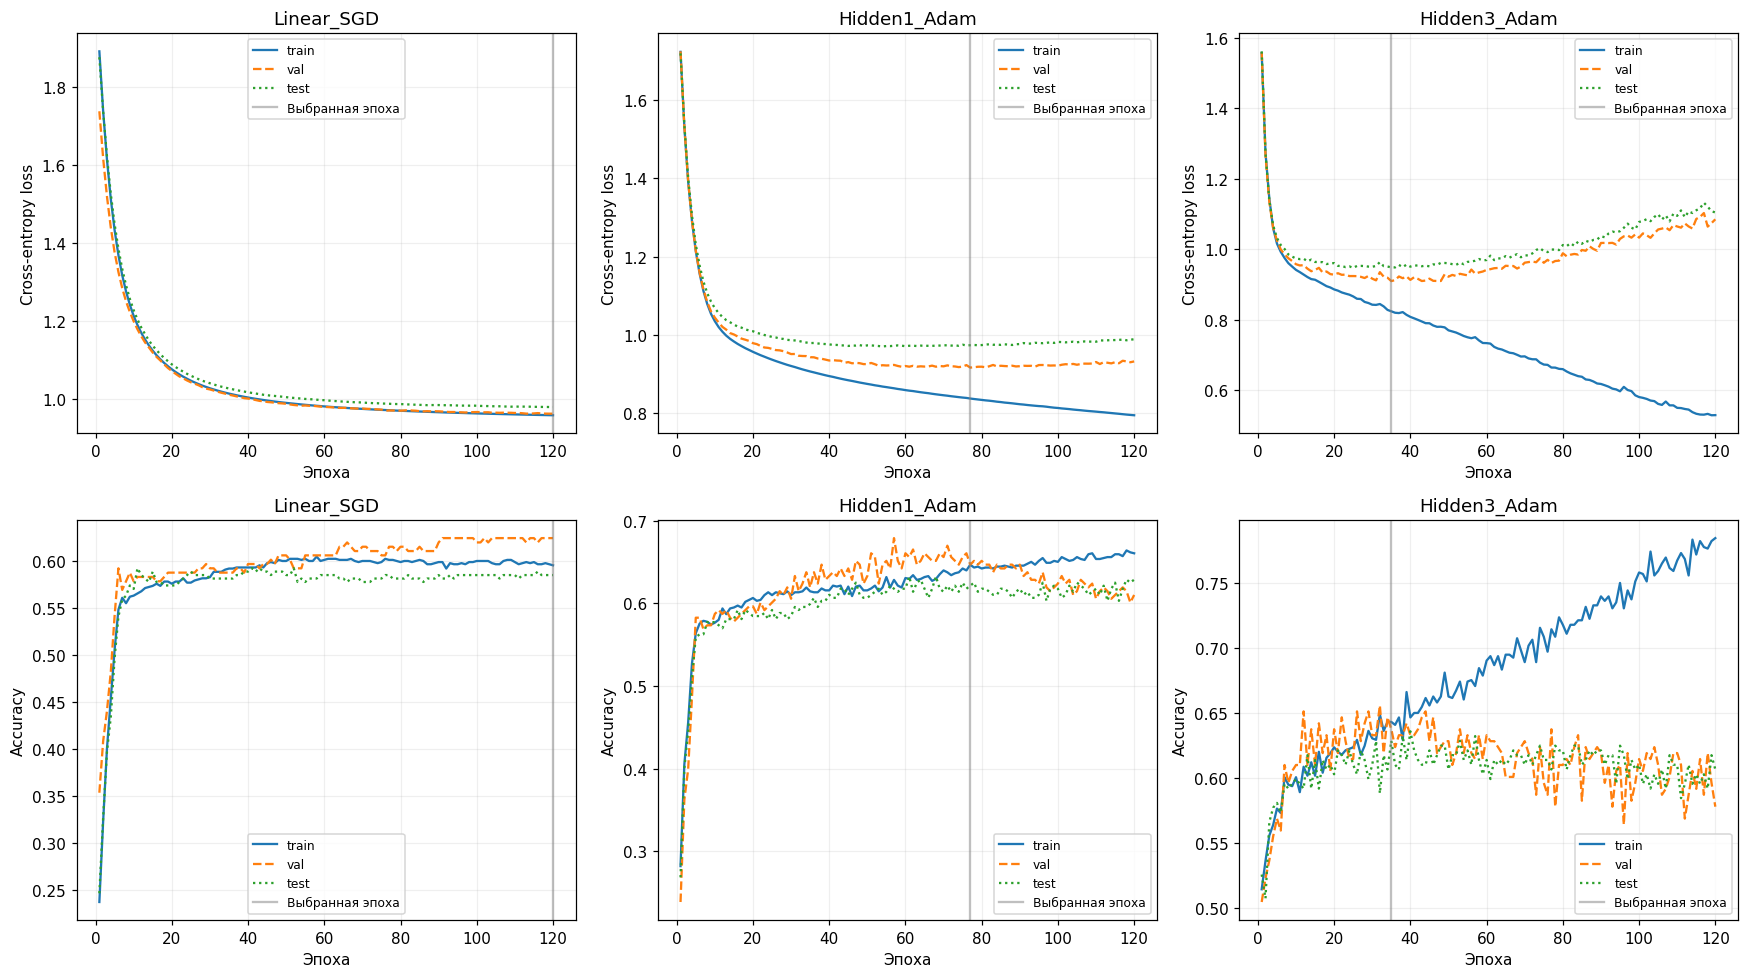

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for col, (name, history) in enumerate(histories.items()):
    for split, style in [("train", "-"), ("val", "--"), ("test", ":")]:
        axes[0, col].plot(history.epoch, history[f"{split}_loss"], style, label=split)
        axes[1, col].plot(history.epoch, history[f"{split}_accuracy"], style, label=split)
    for row in range(2):
        axes[row, col].axvline(best_epochs[name], color="grey", alpha=.5, label="Выбранная эпоха")
        axes[row, col].set(xlabel="Эпоха", title=name)
        axes[row, col].legend(fontsize=8); axes[row, col].grid(alpha=.2)
    axes[0, col].set_ylabel("Cross-entropy loss")
    axes[1, col].set_ylabel("Accuracy")
fig.tight_layout(); show_plot(fig)

## 6. Метрики выбранных чекпойнтов на train, val и test

Базовая test Accuracy при постоянном предсказании самого частого train-класса: 0.4264705882352941
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.67      0.72      0.70       116
           6       0.61      0.66      0.63       107
           7       0.55      0.48      0.52        33
           8       0.00      0.00      0.00         3

    accuracy                           0.63       272
   macro avg       0.31      0.31      0.31       272
weighted avg       0.59      0.63      0.61       272



,model,epoch,split,loss,accuracy,macro_f1
0,Linear_SGD,120,train,0.9584,0.5949,0.2696
1,Linear_SGD,120,val,0.9624,0.6239,0.3288
2,Linear_SGD,120,test,0.9792,0.5846,0.2687
3,Hidden1_Adam,77,train,0.8372,0.6467,0.4165
4,Hidden1_Adam,77,val,0.9163,0.6468,0.3508
5,Hidden1_Adam,77,test,0.9735,0.6213,0.2928
6,Hidden3_Adam,35,train,0.8239,0.6433,0.3709
7,Hidden3_Adam,35,val,0.9096,0.6376,0.3192
8,Hidden3_Adam,35,test,0.9485,0.6287,0.3079


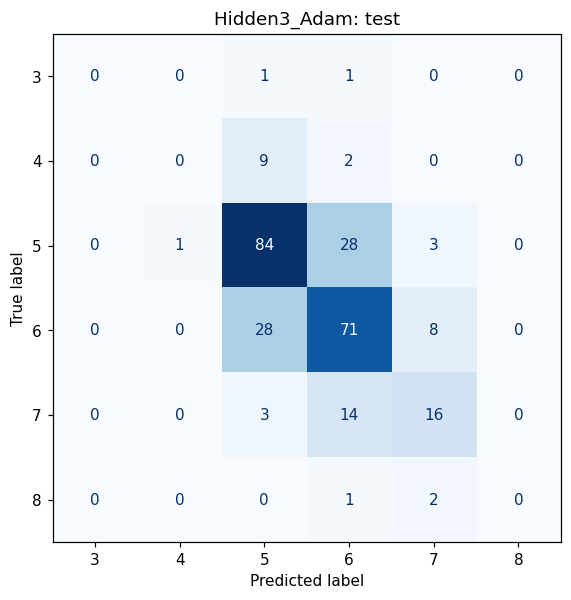

In [6]:
rows = []
for name, net in nets.items():
    for split, loader in eval_loaders.items():
        loss, accuracy, macro_f1 = evaluate(net, loader)
        rows.append({"model": name, "epoch": best_epochs[name], "split": split,
                     "loss": loss, "accuracy": accuracy, "macro_f1": macro_f1})
metrics = pd.DataFrame(rows)
display(metrics.round(4))
metrics.to_csv(ARTIFACTS / "lab4_metrics.csv", index=False)
print("Базовая test Accuracy при постоянном предсказании самого частого train-класса:",
      np.mean(y_test == np.bincount(y_train).argmax()))
selected = nets[selected_name]
with torch.no_grad():
    prediction = selected(torch.tensor(test_array, device=DEVICE)).argmax(1).cpu().numpy()
print(classification_report(y_test, prediction, labels=np.arange(OUTPUT), target_names=[str(c) for c in classes], zero_division=0))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(classes[y_test], classes[prediction], labels=classes, ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"{selected_name}: test")
show_plot(fig)

## 7. Сравнение и выводы

In [7]:
print("Выбранная по validation модель:", selected_name)
for name, history in histories.items():
    row = history.loc[history.epoch.eq(best_epochs[name])].iloc[0]
    print(f"{name}: train acc={row.train_accuracy:.3f}, val acc={row.val_accuracy:.3f}, test acc={row.test_accuracy:.3f}; "
          f"разрыв train−test={row.train_accuracy-row.test_accuracy:.3f}")
    print(f"  val-loss выбранной/последней эпохи: {row.val_loss:.4f}/{history.iloc[-1].val_loss:.4f}")

Выбранная по validation модель: Hidden3_Adam
Linear_SGD: train acc=0.595, val acc=0.624, test acc=0.585; разрыв train−test=0.010
  val-loss выбранной/последней эпохи: 0.9624/0.9624
Hidden1_Adam: train acc=0.647, val acc=0.647, test acc=0.621; разрыв train−test=0.025
  val-loss выбранной/последней эпохи: 0.9163/0.9321
Hidden3_Adam: train acc=0.643, val acc=0.638, test acc=0.629; разрыв train−test=0.015
  val-loss выбранной/последней эпохи: 0.9096/1.0847


**Интерпретация.** Снижение train-loss при росте val-loss указывает на переобучение; поэтому возвращаются лучшие веса по validation. Более глубокая сеть не обязана быть лучше: выборка мала, а классы редких оценок представлены слабо. Если линейная сеть уступает нелинейной и на train, и на validation, это согласуется с ограниченной выразительностью; плохой результат также может быть связан с оптимизацией. Accuracy дополнена macro-F1, поскольку предсказание только оценок 5 и 6 может давать обманчиво высокий результат.

Улучшения: ранняя остановка, подбор lr/регуляризации/ширины по validation, class weights или подбор порогов только на train, дополнительные данные редких оценок. Взвешенная loss не использовалась в этом сравнении, чтобы базовая настройка всех трёх сетей была одинаковой. Разные оптимизаторы и архитектуры означают, что сравнение отражает их сочетание, а не изолированный эффект глубины. Test не участвовал в выборе чекпойнта.

## Фактические результаты и ответы на вопросы

Линейная сеть получила test Accuracy ≈ 0,585, сеть с одним скрытым слоем — ≈0,621, с тремя — ≈0,629. По минимальному val-loss была выбрана трёхслойная скрытая архитектура на 35-й эпохе; выбор совпал с лучшей наблюдаемой test Accuracy, но тест не использовался как критерий.

У глубокой сети val-loss выбранной эпохи ≈0,910, а последней — ≈1,085, при снижении train-loss до ≈0,530. Это наблюдаемый признак переобучения поздних эпох, поэтому сохранён чекпойнт 35-й эпохи. Однослойная сеть продолжала улучшаться до 120-й эпохи: её режим ещё можно исследовать, но утверждать окончательную сходимость нельзя.

У выбранной модели test macro-F1 ≈0,308. Матрица ошибок показывает, что редкие оценки 3, 4 и 8 распознаются плохо, несмотря на Accuracy ≈0,629. Следовательно, задача не решена идеально. Результаты №3 и №4 нельзя трактовать как чистое сравнение семейств: в №4 часть внешнего train выделена для validation, и обучающих примеров меньше.